In [1]:
import numpy as np
import pandas as pd

#models ml tools 
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.preprocessing import LabelEncoder

from pathlib import Path


from econml.dml import LinearDML, CausalForestDML
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier


import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from pathlib import Path
import joblib

DATA_DIR = Path(
    r"E:\internhips\infotact solutions\Dynamic Pricing via Double Machine Learning\backend\data\processed"
)

X = joblib.load(DATA_DIR / "X.pkl")
T = joblib.load(DATA_DIR / "T.pkl")
Y = joblib.load(DATA_DIR / "Y.pkl")



# Split into training and testing sets
X_train, X_test, T_train, T_test, Y_train, Y_test = train_test_split(
    X,
    T,
    Y,
    test_size=0.2,
    random_state=42
)


# Model Training


m1 : y[conversion] - will customer purchase

How much receiving an email affects conversion
after removing confounding effects.

m 2: y[spend] - how much an extra revenue email Generates 

# -------------------------
# creating base model

In [3]:
model_y = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1,
)

model_t = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1,
)

In [4]:
print(Y_train.dtype)
print(T_train.dtype)

print(Y_train.unique()[:10])
print(T_train.unique()[:10])


print(X_train.dtypes)

int64
int64
[0 1]
[1 0]
recency       int64
history     float64
mens          int64
womens        int64
zip_code      int64
newbie        int64
channel       int64
dtype: object


In [5]:
# so here combine both model using dml 
dml = CausalForestDML(
    model_y=model_y,
    model_t=model_t,
    discrete_treatment=True,
    n_estimators=200,
    random_state=42,
)

In [6]:
dml.fit(
    Y_train,
    T_train,
    X=X_train
)

# predict indivdual tratment effect

In [7]:
ite = dml.effect(X_test, T0=0, T1=1)

print(ite[:5])

[ 0.00526572  0.00328004  0.01406406  0.01574321 -0.00471378]


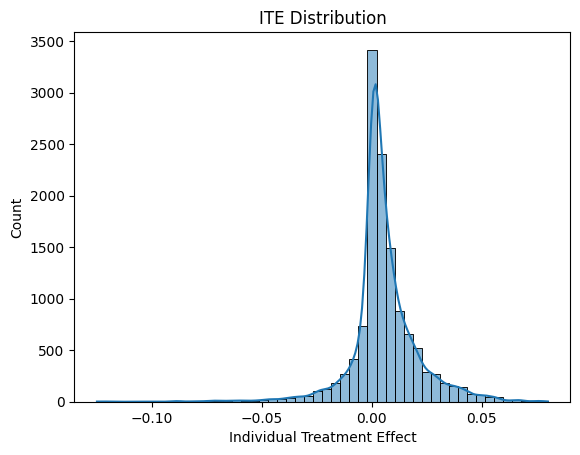

In [8]:
sns.histplot(
    ite,
    bins=50,
    kde=True
)

plt.title("ITE Distribution")
plt.xlabel("Individual Treatment Effect")
plt.show()

In [9]:
print("Min ITE:", ite.min())
print("Max ITE:", ite.max())
print("Mean ITE:", ite.mean())

Min ITE: -0.1250362843841181
Max ITE: 0.08002193226678324
Mean ITE: 0.005530125207289422


In [10]:
results = X_test.copy()

results["ITE"] = ite

top_customers = results.sort_values(
    "ITE",
    ascending=False
)

print(top_customers.head(20))

       recency  history  mens  womens  zip_code  newbie  channel       ITE
4399         1    62.16     0       1         0       0        2  0.080022
23900        1    67.34     0       1         0       0        2  0.078776
37426        1    72.00     0       1         1       0        1  0.076054
22133        4    29.99     1       0         2       0        2  0.075990
2359         4    29.99     1       0         2       0        2  0.075990
3861         4    29.99     1       0         2       0        2  0.075990
17521        4    29.99     1       0         2       0        2  0.075990
38094        4    29.99     1       0         2       0        2  0.075990
10206        4    29.99     1       0         2       0        2  0.075990
12584        4    29.99     1       0         2       0        2  0.075990
42479        2    33.34     0       1         2       1        2  0.074084
53916        4   302.17     1       1         2       0        2  0.072232
17805        1   357.01  

In [11]:
results["segment"] = "Low"

results.loc[
    results["ITE"] > 0.02,
    "segment"
] = "High"

results.loc[
    (results["ITE"] > 0.01)
    &
    (results["ITE"] <= 0.02),
    "segment"
] = "Medium"

print(results["segment"])
print(results["segment"].unique())
# print(results["segment"].unique().count)

33042       Low
7209        Low
24367    Medium
19599    Medium
31465       Low
          ...  
29518      High
40886       Low
19792       Low
31101    Medium
54307       Low
Name: segment, Length: 12800, dtype: object
['Low' 'Medium' 'High']


In [12]:
print(results["segment"].value_counts())

segment
Low       9333
Medium    1888
High      1579
Name: count, dtype: int64


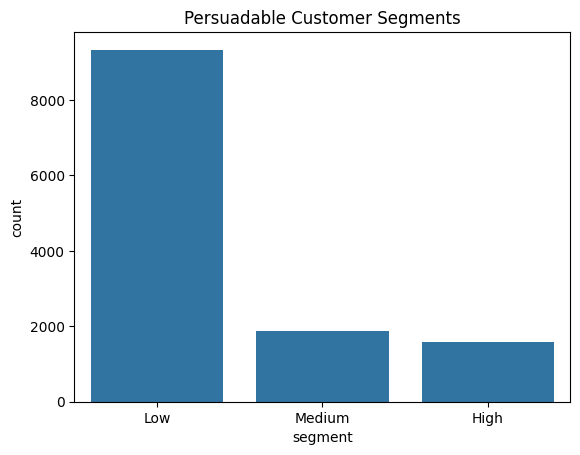

In [13]:
sns.countplot(
    data=results,
    x="segment",
    order=["Low", "Medium", "High"]
)

plt.title("Persuadable Customer Segments")
plt.show()

In [14]:
top_customers = results.sort_values(
    "ITE",
    ascending=False
)

print(top_customers.head(20))

       recency  history  mens  womens  zip_code  newbie  channel       ITE  \
4399         1    62.16     0       1         0       0        2  0.080022   
23900        1    67.34     0       1         0       0        2  0.078776   
37426        1    72.00     0       1         1       0        1  0.076054   
22133        4    29.99     1       0         2       0        2  0.075990   
2359         4    29.99     1       0         2       0        2  0.075990   
3861         4    29.99     1       0         2       0        2  0.075990   
17521        4    29.99     1       0         2       0        2  0.075990   
38094        4    29.99     1       0         2       0        2  0.075990   
10206        4    29.99     1       0         2       0        2  0.075990   
12584        4    29.99     1       0         2       0        2  0.075990   
42479        2    33.34     0       1         2       1        2  0.074084   
53916        4   302.17     1       1         2       0        2

In [15]:
profit_per_conversion = 20

results["expected_revenue"] = (
    results["ITE"] *
    profit_per_conversion
)

In [19]:
# results["discount"] = 0

# results.loc[
#     results["segment"]=="High",
#     "discount"
# ] = 20

# results.loc[
#     results["segment"]=="Medium",
#     "discount"
# ] = 10

# results

In [20]:
results["cost"] = results["discount"]
print(
    results["cost"].sum()
)

50460


In [21]:
final_targets = (
    results
    .sort_values(
        "ITE",
        ascending=False
    )
)

results.to_csv(
    "customer_recommendations.csv",
    index=False
)

# SAving the model

In [23]:
import joblib
from pathlib import Path
from datetime import datetime, timezone

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "model": dml,
    "feature_columns": list(X_train.columns),
    "treatment_definition": "1 = Womens E-Mail, 0 = No E-Mail",
    "outcome": "conversion",
    "model_type": "CausalForestDML",
    "trained_at": datetime.now(timezone.utc).isoformat(),
}

joblib.dump(
    model_bundle,
    MODEL_DIR / "conversion_causal_forest_v1.joblib",
    compress=3,
)

['models\\conversion_causal_forest_v1.joblib']